In [ ]:
import pandas as pd
import numpy as np
import re, html, unicodedata
from urllib.parse import unquote

geo = pd.read_csv('olist_geolocation_dataset.csv',
                  dtype={'geolocation_zip_code_prefix': str})   # keeps leading zeros
print(geo.shape)

(1000163, 5)


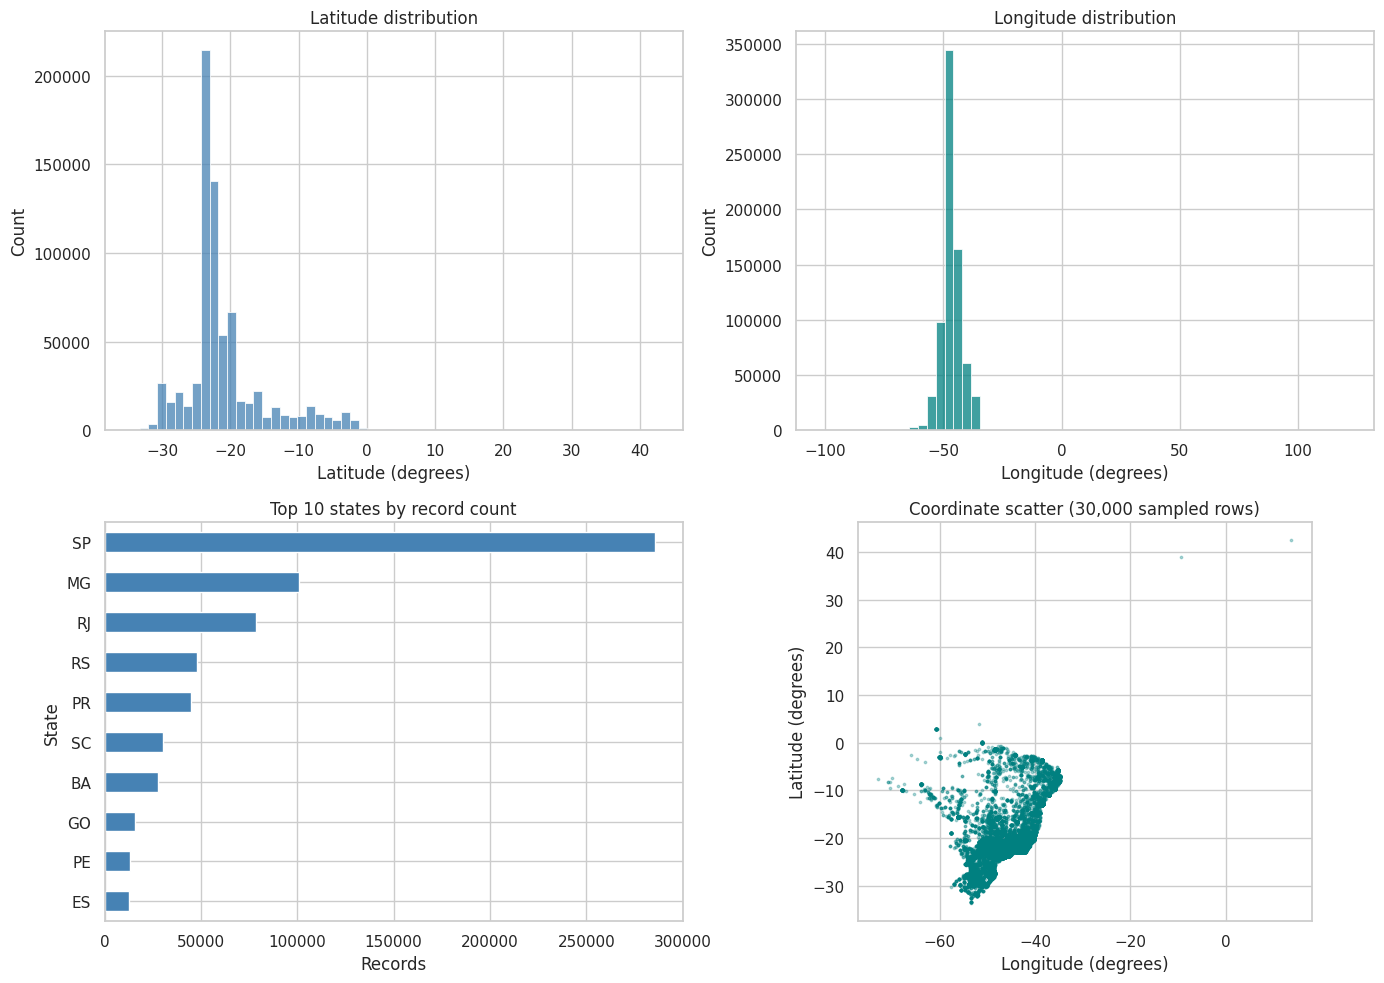

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

sns.set_theme(style="whitegrid")

# Work on a copy of your cleaned dataset
df = geo.copy()

lat = "geolocation_lat"
lng = "geolocation_lng"
numeric_cols = [lat, lng]

plot_sample = df.sample(n=min(30000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Latitude distribution
sns.histplot(data=df, x=lat, bins=60, color="steelblue", ax=axes[0, 0])
axes[0, 0].set(title="Latitude distribution", xlabel="Latitude (degrees)")

# Longitude distribution
sns.histplot(data=df, x=lng, bins=60, color="teal", ax=axes[0, 1])
axes[0, 1].set(title="Longitude distribution", xlabel="Longitude (degrees)")

# Number of records, not number of customers or orders
df["geolocation_state"].value_counts().head(10).sort_values().plot.barh(
    ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set(
    title="Top 10 states by record count", xlabel="Records", ylabel="State"
)

# Geographic distribution
axes[1, 1].scatter(
    plot_sample[lng], plot_sample[lat], s=3, alpha=0.3, color="teal"
)
axes[1, 1].set(
    title=f"Coordinate scatter ({len(plot_sample):,} sampled rows)",
    xlabel="Longitude (degrees)",
    ylabel="Latitude (degrees)"
)
axes[1, 1].set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()

In [ ]:
#Rule1: zip is a 5-digit string with its leading zeros
geo['geolocation_zip_code_prefix'] = geo['geolocation_zip_code_prefix'].str.strip().str.zfill(5)

valid_zip = geo['geolocation_zip_code_prefix'].str.fullmatch(r'\d{5}')
print("Invalid zip codes:", (~valid_zip).sum())
geo = geo[valid_zip]

Invalid zip codes: 0


In [ ]:
#Rule2: city is lowercase, with no accents and no extra spaces
def clean_city(city):
    city = unquote(str(city))                             # %26apos%3b  ->  &apos;
    city = html.unescape(city)                            # &oacute; -> ó ,  &apos; -> '
    city = city.replace('a£', 'a').replace('a³', 'o')     # broken text: sa£o -> sao, maceia³ -> maceio
    city = unicodedata.normalize('NFKD', city).encode('ascii', 'ignore').decode('ascii')  # remove accents
    city = city.lower()                                   # lowercase
    city = city.replace('`', "'")                         # d`oeste -> d'oeste
    city = re.sub(r"\bd\s{2,}", "d'", city)               # pau d  arco -> pau d'arco
    city = re.sub(r"^[^a-z0-9]+", "", city)               # junk at start: ...arraial, ´teresopolis
    city = re.sub(r"\s+", " ", city).strip()              # extra spaces
    return city

print("Distinct cities before:", geo['geolocation_city'].nunique())
geo['geolocation_city'] = geo['geolocation_city'].map(clean_city)
print("Distinct cities after: ", geo['geolocation_city'].nunique())

Distinct cities before: 8011
Distinct cities after:  5955


In [ ]:
#Rule3: lat/lng are inside Brazil
in_brazil = (geo['geolocation_lat'].between(-33.75, 5.27) &
             geo['geolocation_lng'].between(-74.0, -28.8))

print("Rows outside Brazil:", (~in_brazil).sum())
geo = geo[in_brazil]

Rows outside Brazil: 31


In [ ]:
#Rule4: each zip belongs to one state
zip_state = geo.groupby('geolocation_zip_code_prefix')['geolocation_state'].agg(lambda s: s.mode()[0])
right_state = geo['geolocation_state'] == geo['geolocation_zip_code_prefix'].map(zip_state)

print("Rows with the wrong state:", (~right_state).sum())
geo = geo[right_state]

Rows with the wrong state: 8


In [ ]:
#Rule5: all points for one zip sit close together
MAX_KM = 50
z = 'geolocation_zip_code_prefix'

med_lat = geo.groupby(z)['geolocation_lat'].transform('median')
med_lng = geo.groupby(z)['geolocation_lng'].transform('median')

# distance in km between each point and its zip center (haversine formula)
lat1, lng1, lat2, lng2 = map(np.radians, [geo['geolocation_lat'], geo['geolocation_lng'], med_lat, med_lng])
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2)**2
dist_km = 6371 * 2 * np.arcsin(np.sqrt(a))

close = dist_km <= MAX_KM
zip_has_close = close.groupby(geo[z]).transform('any')
too_far = ~close & zip_has_close

print("Points too far from their zip:", too_far.sum())
geo = geo[~too_far]

Points too far from their zip: 948


In [ ]:
#Rule6: no exact duplicate rows
print("Duplicate rows:", geo.duplicated().sum())
geo = geo.drop_duplicates().reset_index(drop=True)
print(geo.shape)

Duplicate rows: 261623
(737584, 5)


In [ ]:
# checks
print("Duplicates:          ", geo.duplicated().sum())
print("Zip not 5 digits:    ", (~geo[z].str.fullmatch(r'\d{5}')).sum())
print("Outside Brazil:      ", (~(geo['geolocation_lat'].between(-33.75, 5.27) &
                                  geo['geolocation_lng'].between(-74.0, -28.8))).sum())
print("Zips with >1 state:  ", (geo.groupby(z)['geolocation_state'].nunique() > 1).sum())
print("Cities not lowercase:", (geo['geolocation_city'] != geo['geolocation_city'].str.lower()).sum())
print("Cities with accents: ", geo['geolocation_city'].str.contains(r'[^\x00-\x7F]').sum())
print("Cities extra spaces: ", geo['geolocation_city'].str.contains(r'^\s|\s$|\s\s').sum())

Duplicates:           0
Zip not 5 digits:     0
Outside Brazil:       13
Zips with >1 state:   0
Cities not lowercase: 0
Cities with accents:  63364
Cities extra spaces:  12


In [ ]:
from google.colab import files

geo.to_csv('olist_geolocation_clean.csv', index=False)
files.download('olist_geolocation_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
geo.head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,01037,-23.545621,-46.639292,sao paulo,SP
1,01046,-23.546081,-46.644820,sao paulo,SP
2,01046,-23.546129,-46.642951,sao paulo,SP
3,01041,-23.544392,-46.639499,sao paulo,SP
4,01035,-23.541578,-46.641607,sao paulo,SP
5,01012,-23.547762,-46.635361,são paulo,SP
6,01047,-23.546273,-46.641225,sao paulo,SP
7,01013,-23.546923,-46.634264,sao paulo,SP
8,01029,-23.543769,-46.634278,sao paulo,SP
9,01011,-23.547640,-46.636032,sao paulo,SP


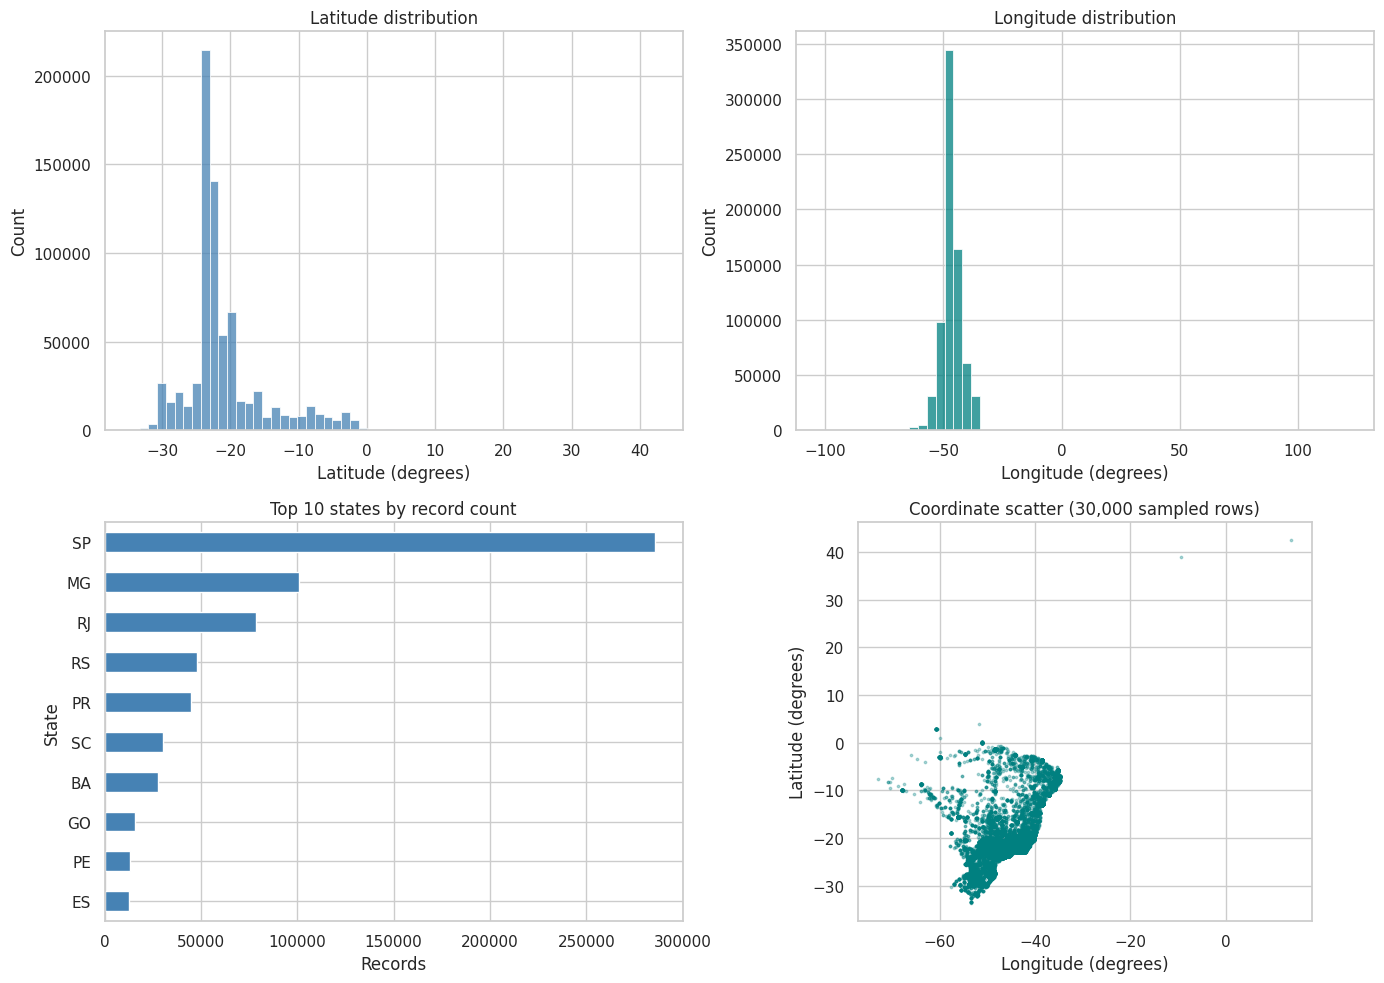

In [ ]:
sns.set_theme(style="whitegrid")

# Work on a copy of your cleaned dataset
df = geo.copy()

lat = "geolocation_lat"
lng = "geolocation_lng"
numeric_cols = [lat, lng]

plot_sample = df.sample(n=min(30000, len(df)), random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Latitude distribution
sns.histplot(data=df, x=lat, bins=60, color="steelblue", ax=axes[0, 0])
axes[0, 0].set(title="Latitude distribution", xlabel="Latitude (degrees)")

# Longitude distribution
sns.histplot(data=df, x=lng, bins=60, color="teal", ax=axes[0, 1])
axes[0, 1].set(title="Longitude distribution", xlabel="Longitude (degrees)")

# Number of records, not number of customers or orders
df["geolocation_state"].value_counts().head(10).sort_values().plot.barh(
    ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set(
    title="Top 10 states by record count", xlabel="Records", ylabel="State"
)

# Geographic distribution
axes[1, 1].scatter(
    plot_sample[lng], plot_sample[lat], s=3, alpha=0.3, color="teal"
)
axes[1, 1].set(
    title=f"Coordinate scatter ({len(plot_sample):,} sampled rows)",
    xlabel="Longitude (degrees)",
    ylabel="Latitude (degrees)"
)
axes[1, 1].set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()